# Lid-Driven Cavity Flow Solver

In this project I solve the 2D lid-driven cavity flow using the stream function–vorticity method in Python. I use finite differences and check my results with the benchmark data of Ghia et al. (1982). At the end I use the solver to make a dataset for a machine learning model.

## 1. Setup and Grid

First I set up the problem. The cavity is a unit square (0 to 1 in x and y). The top wall (lid) moves with speed 1 and the other three walls are fixed. I start with Re = 100 and a 41×41 grid.

I make arrays for the stream function ψ, vorticity ω, and the velocities u and v. All of them start from zero. In the arrays the first index is y (row) and the second index is x (column).

h = 0.025 | dt = 0.0125


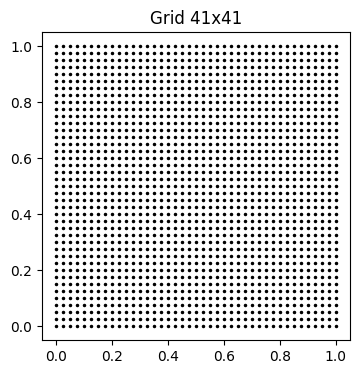

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
Re = 100          # Reynolds number
N = 41            # grid points in each direction
L = 1.0           # domain size
U_lid = 1.0       # lid velocity

# Grid
h = L / (N - 1)   # grid spacing (dx = dy = h)
x = np.linspace(0, L, N)
y = np.linspace(0, L, N)
X, Y = np.meshgrid(x, y)   # X[j, i], Y[j, i]: row = y index, column = x index

# Fields (initially zero)
psi   = np.zeros((N, N))   # stream function
omega = np.zeros((N, N))   # vorticity
u     = np.zeros((N, N))
v     = np.zeros((N, N))

# Time step (stability: explicit scheme)
dt = 0.25 * h**2 * Re     # starting guess, we will refine in a later step
dt = min(dt, h / U_lid * 0.5)

print("h =", h, "| dt =", dt)

# Quick check: plot the grid
plt.figure(figsize=(4, 4))
plt.plot(X, Y, 'k.', markersize=3)
plt.title(f"Grid {N}x{N}")
plt.gca().set_aspect('equal')
plt.show()

**Result:** The grid spacing is h = 0.025 and the time step is dt = 0.0125. The plot shows a uniform 41×41 grid.

## 2. Poisson Equation Solver

At every time step I need ψ from the vorticity ω. They are connected by the Poisson equation:

$$\nabla^2 \psi = -\omega$$

I solve it with finite differences and the Jacobi method. For each inner point:

$$\psi_{i,j} = \frac{1}{4}\left(\psi_{i+1,j} + \psi_{i-1,j} + \psi_{i,j+1} + \psi_{i,j-1} + h^2 \omega_{i,j}\right)$$

I repeat this until ψ stops changing. On all walls ψ = 0.

To test the solver I choose ψ = sin(πx) sin(πy). Then ω = 2π² sin(πx) sin(πy). I give this ω to the solver and check if it gives back the same ψ.

Iterations: 2604 | last change: 9.974936829859615e-07
Max error vs exact solution: 0.00019161650158006083


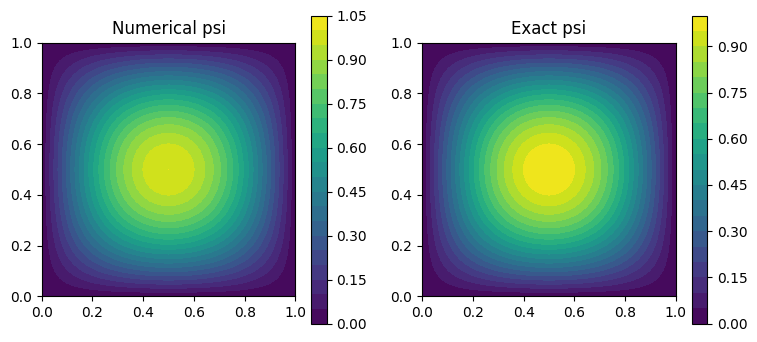

In [2]:
def solve_poisson(psi, omega, h, tol=1e-6, max_iter=20000):
    """Solve  laplacian(psi) = -omega  with psi = 0 on boundary (Jacobi)."""
    for it in range(1, max_iter + 1):
        psi_old = psi.copy()
        psi[1:-1, 1:-1] = 0.25 * (
            psi_old[1:-1, 2:] + psi_old[1:-1, :-2] +   # right, left  (x direction)
            psi_old[2:, 1:-1] + psi_old[:-2, 1:-1] +   # up, down     (y direction)
            h**2 * omega[1:-1, 1:-1]
        )
        err = np.max(np.abs(psi - psi_old))
        if err < tol:
            break
    return psi, it, err


# ---- TEST with a known exact solution ----
# If psi_exact = sin(pi x) sin(pi y), then omega = 2 pi^2 sin(pi x) sin(pi y)
psi_exact   = np.sin(np.pi * X) * np.sin(np.pi * Y)
omega_test  = 2 * np.pi**2 * psi_exact
psi_test    = np.zeros((N, N))

psi_test, iters, err = solve_poisson(psi_test, omega_test, h)

print("Iterations:", iters, "| last change:", err)
print("Max error vs exact solution:", np.max(np.abs(psi_test - psi_exact)))

# Plot numerical vs exact
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
c1 = ax[0].contourf(X, Y, psi_test, 20); ax[0].set_title("Numerical psi")
c2 = ax[1].contourf(X, Y, psi_exact, 20); ax[1].set_title("Exact psi")
for a in ax: a.set_aspect('equal')
plt.colorbar(c1, ax=ax[0]); plt.colorbar(c2, ax=ax[1])
plt.show()

**Result:** The solver took 2604 iterations. The maximum error compared with the exact solution is 1.9 × 10⁻⁴, and the two contour plots look the same.

**Conclusion:** The Poisson solver works correctly, so I can use it in the main solver.

## 3. Wall Vorticity and Velocity

The vorticity on the walls is not known in advance, so I use Thom's formula. Here ψ_adj is ψ at the point next to the wall:

- fixed walls: ω = −2 ψ_adj / h²
- moving lid: ω = −2 ψ_adj / h² − 2U / h

The velocities come from ψ:

$$u = \frac{\partial \psi}{\partial y}, \qquad v = -\frac{\partial \psi}{\partial x}$$

To test it I take ψ = 0 (fluid at rest). Then only the lid should have vorticity, equal to −2U/h = −80.

In [3]:
def apply_vorticity_bc(omega, psi, h, U_lid):
    """Thom's formula for wall vorticity (psi = 0 on all walls)."""
    omega[0, :]  = -2.0 * psi[1, :]  / h**2                    # bottom
    omega[-1, :] = -2.0 * psi[-2, :] / h**2 - 2.0 * U_lid / h  # top (moving lid)
    omega[:, 0]  = -2.0 * psi[:, 1]  / h**2                    # left
    omega[:, -1] = -2.0 * psi[:, -2] / h**2                    # right
    return omega


def compute_velocity(psi, h, U_lid):
    """u = dpsi/dy, v = -dpsi/dx (central differences inside)."""
    u = np.zeros_like(psi)
    v = np.zeros_like(psi)
    u[1:-1, 1:-1] =  (psi[2:, 1:-1] - psi[:-2, 1:-1]) / (2 * h)
    v[1:-1, 1:-1] = -(psi[1:-1, 2:] - psi[1:-1, :-2]) / (2 * h)
    u[-1, :] = U_lid          # lid moves with u = U_lid
    return u, v


# ---- quick test with psi = 0 (flow at rest) ----
psi   = np.zeros((N, N))
omega = np.zeros((N, N))
omega = apply_vorticity_bc(omega, psi, h, U_lid)
u, v  = compute_velocity(psi, h, U_lid)

print("omega on top lid (expect -2U/h =", -2 * U_lid / h, "):", omega[-1, 5])
print("omega on bottom wall (expect 0):", omega[0, 5])
print("u at lid:", u[-1, 5], "| u inside:", u[20, 20])

omega on top lid (expect -2U/h = -80.0 ): -80.0
omega on bottom wall (expect 0): -0.0
u at lid: 1.0 | u inside: 0.0


**Result:** For the fluid at rest, the vorticity on the lid is −80 and on the bottom wall it is 0. The velocity u is 1 on the lid and 0 inside.

**Conclusion:** The wall conditions work as expected.

## 4. Time Stepping

Now I put everything together and let the flow develop in time. The vorticity equation is:

$$\frac{\partial \omega}{\partial t} = -u\frac{\partial \omega}{\partial x} - v\frac{\partial \omega}{\partial y} + \frac{1}{Re}\nabla^2\omega$$

I use the explicit Euler method in time and central differences in space. In every time step I do these four things:

1. Update the vorticity inside the cavity.
2. Solve the Poisson equation to get the new ψ.
3. Update the vorticity on the walls with Thom's formula.
4. Calculate u and v from ψ.

I stop when the largest change in ω between two steps is less than 1e-4. This means the flow has reached steady state.

step   500 | t =   6.250 | max change = 6.95e-04
Stopped at step 792, t = 9.900, last change = 9.74e-05
psi_min = -0.1013 at (x, y) = (0.625, 0.750)


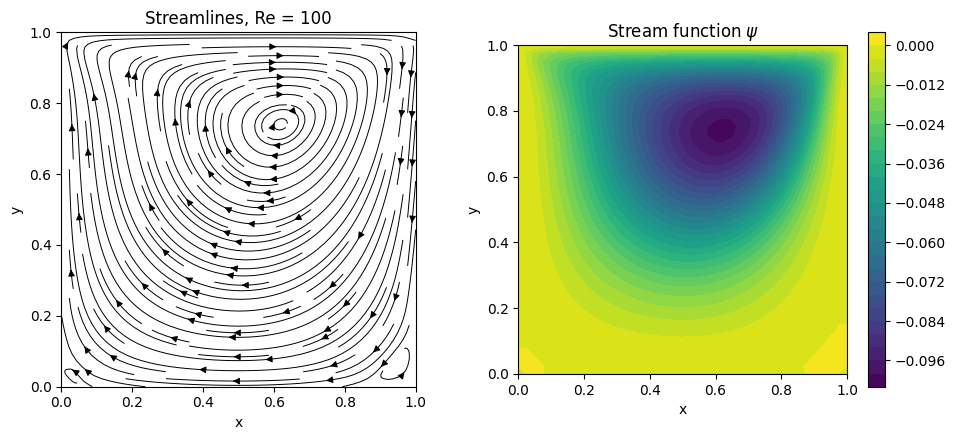

In [4]:
def solve_cavity(Re, N=41, U_lid=1.0, tol=1e-4, max_steps=20000, print_every=500):
    """Lid-driven cavity, stream function-vorticity, explicit time stepping."""
    h  = 1.0 / (N - 1)
    dt = min(0.25 * h**2 * Re, 0.5 * h / U_lid)

    psi   = np.zeros((N, N))
    omega = np.zeros((N, N))
    omega = apply_vorticity_bc(omega, psi, h, U_lid)
    u, v  = compute_velocity(psi, h, U_lid)

    for n in range(1, max_steps + 1):
        w = omega
        dwdx = (w[1:-1, 2:] - w[1:-1, :-2]) / (2 * h)
        dwdy = (w[2:, 1:-1] - w[:-2, 1:-1]) / (2 * h)
        lap  = (w[1:-1, 2:] + w[1:-1, :-2] + w[2:, 1:-1] + w[:-2, 1:-1]
                - 4 * w[1:-1, 1:-1]) / h**2

        # 1) interior vorticity update
        omega_new = w.copy()
        omega_new[1:-1, 1:-1] = w[1:-1, 1:-1] + dt * (
            -u[1:-1, 1:-1] * dwdx - v[1:-1, 1:-1] * dwdy + lap / Re)

        # 2) stream function, 3) wall vorticity, 4) velocity
        psi, _, _ = solve_poisson(psi, omega_new, h, tol=1e-7, max_iter=5000)
        omega_new = apply_vorticity_bc(omega_new, psi, h, U_lid)
        u, v = compute_velocity(psi, h, U_lid)

        change = np.max(np.abs(omega_new - omega))
        omega = omega_new

        if print_every and n % print_every == 0:
            print(f"step {n:5d} | t = {n*dt:7.3f} | max change = {change:.2e}")
        if change < tol:
            break

    return psi, omega, u, v, n, dt, change


# ---- Run for Re = 100 ----
psi, omega, u, v, n, dt, change = solve_cavity(Re=100, N=41)
print(f"Stopped at step {n}, t = {n*dt:.3f}, last change = {change:.2e}")

# Primary vortex location
j, i = np.unravel_index(np.argmin(psi), psi.shape)
print(f"psi_min = {psi[j, i]:.4f} at (x, y) = ({x[i]:.3f}, {y[j]:.3f})")

# Plots: streamlines and stream function contours
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].streamplot(x, y, u, v, density=1.5, color='k', linewidth=0.7)
ax[0].set_title("Streamlines, Re = 100")
c = ax[1].contourf(X, Y, psi, 25, cmap='viridis')
ax[1].set_title(r"Stream function $\psi$")
plt.colorbar(c, ax=ax[1])
for a in ax:
    a.set_aspect('equal'); a.set_xlabel('x'); a.set_ylabel('y')
plt.tight_layout()
plt.show()

**Result:** The solution reached steady state after 792 time steps (t ≈ 9.9). The main vortex has ψ_min ≈ −0.101 at (0.625, 0.750). The streamlines show one big vortex in the upper middle of the cavity and two small vortices in the bottom corners.

**Conclusion:** The flow looks like the known lid-driven cavity flow at Re = 100.

## 5. Checking with Ghia et al. (1982)

To check my solver I compare it with the benchmark data of Ghia, Ghia and Shin (1982) for Re = 100. I look at two lines through the centre of the cavity:

- u along the vertical line x = 0.5
- v along the horizontal line y = 0.5

The benchmark points are not on my grid, so I use interpolation to get my values at the same points. Then I calculate the maximum error and the RMS error.

u centerline: max error = 0.0065, RMS error = 0.0032
v centerline: max error = 0.0047, RMS error = 0.0028


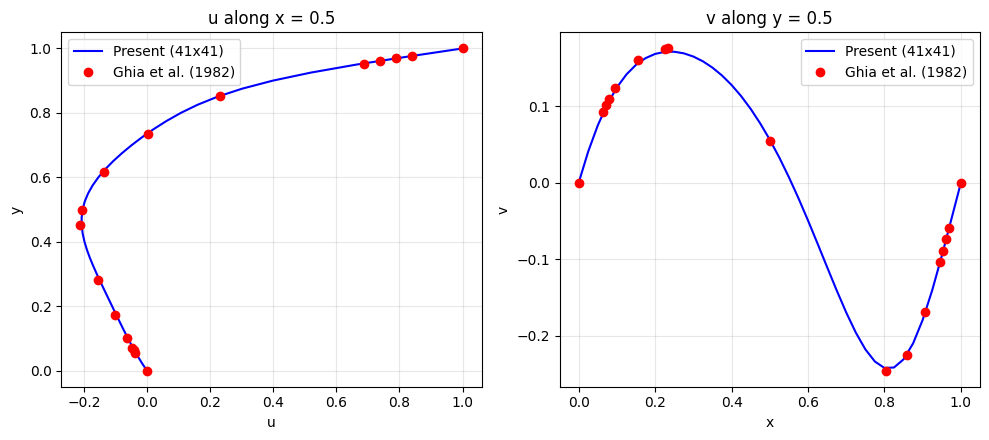

In [5]:
# Ghia et al. (1982), Re = 100: u along vertical centerline (x = 0.5)
ghia_y = np.array([0.0000, 0.0547, 0.0625, 0.0703, 0.1016, 0.1719, 0.2813, 0.4531,
                   0.5000, 0.6172, 0.7344, 0.8516, 0.9531, 0.9609, 0.9688, 0.9766, 1.0000])
ghia_u = np.array([0.00000, -0.03717, -0.04192, -0.04775, -0.06434, -0.10150, -0.15662, -0.21090,
                   -0.20581, -0.13641, 0.00332, 0.23151, 0.68717, 0.73722, 0.78871, 0.84123, 1.00000])

# Ghia et al. (1982), Re = 100: v along horizontal centerline (y = 0.5)
ghia_x = np.array([0.0000, 0.0625, 0.0703, 0.0781, 0.0938, 0.1563, 0.2266, 0.2344,
                   0.5000, 0.8047, 0.8594, 0.9063, 0.9453, 0.9531, 0.9609, 0.9688, 1.0000])
ghia_v = np.array([0.00000, 0.09233, 0.10091, 0.10890, 0.12317, 0.16077, 0.17507, 0.17527,
                   0.05454, -0.24533, -0.22445, -0.16914, -0.10313, -0.08864, -0.07391, -0.05906, 0.00000])

mid = (N - 1) // 2                      # index of the centerline (x = 0.5 or y = 0.5)
u_num = np.interp(ghia_y, y, u[:, mid])  # u(x=0.5, y) at Ghia's y locations
v_num = np.interp(ghia_x, x, v[mid, :])  # v(x, y=0.5) at Ghia's x locations

err_u = u_num - ghia_u
err_v = v_num - ghia_v
print(f"u centerline: max error = {np.max(np.abs(err_u)):.4f}, RMS error = {np.sqrt(np.mean(err_u**2)):.4f}")
print(f"v centerline: max error = {np.max(np.abs(err_v)):.4f}, RMS error = {np.sqrt(np.mean(err_v**2)):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].plot(u[:, mid], y, 'b-', label='Present (41x41)')
ax[0].plot(ghia_u, ghia_y, 'ro', label='Ghia et al. (1982)')
ax[0].set_xlabel('u'); ax[0].set_ylabel('y'); ax[0].set_title('u along x = 0.5')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(x, v[mid, :], 'b-', label='Present (41x41)')
ax[1].plot(ghia_x, ghia_v, 'ro', label='Ghia et al. (1982)')
ax[1].set_xlabel('x'); ax[1].set_ylabel('v'); ax[1].set_title('v along y = 0.5')
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Result:** On the 41×41 grid the maximum error is 0.0065 for u (RMS 0.0032) and 0.0047 for v (RMS 0.0028). In the plots the blue line goes through the red benchmark points.

**Conclusion:** My results are very close to the benchmark, so the solver is correct at Re = 100.

## 6. Higher Reynolds Numbers (Re = 400 and 1000)

In this step I test my solver at Re = 400 and Re = 1000 and compare it again with the Ghia et al. (1982) data.

At higher Re the flow becomes harder to solve, so I made two changes:
- I use a finer grid of 129×129, because a coarse grid does not give good results at high Re.
- The old Jacobi method was too slow for this, so I use a faster tool (`splu` from SciPy) to solve the Poisson equation. The equation is the same, only the way of solving it is faster.

I stop the simulation when the change in vorticity between two time steps is less than 1e-6.

Re = 400: steps = 10297, t = 40.2, psi_min = -0.1128 at (0.555, 0.609)
   u: max error = 0.0054, RMS = 0.0026
   v: max error = 0.0030, RMS = 0.0020
Re = 1000: steps = 18574, t = 72.6, psi_min = -0.1154 at (0.531, 0.570)
   u: max error = 0.0137, RMS = 0.0082
   v: max error = 0.0080, RMS = 0.0054


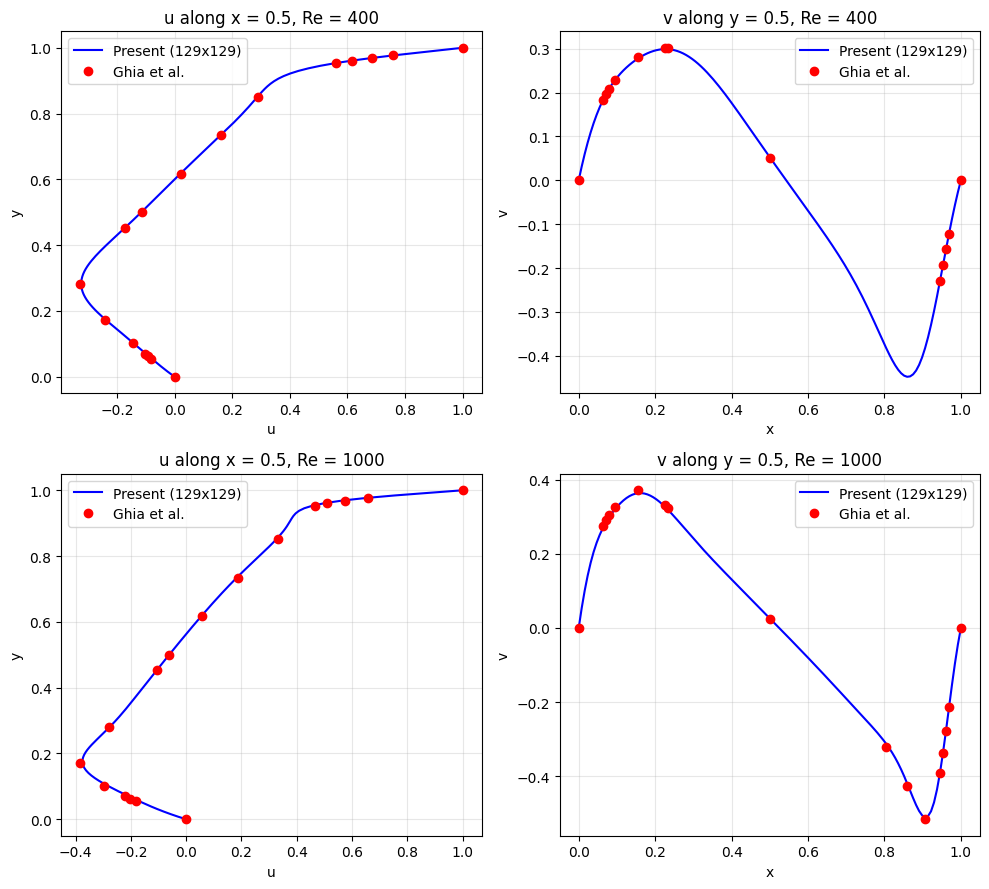

In [6]:
import scipy.sparse as sp
from scipy.sparse.linalg import splu

def solve_cavity_fast(Re, N=41, U_lid=1.0, tol=1e-6, max_steps=100000):
    """Same scheme as solve_cavity, but the Poisson equation uses a sparse LU solve."""
    h  = 1.0 / (N - 1)
    dt = min(0.25 * h**2 * Re, 0.5 * h / U_lid)

    m = N - 2                                   # number of interior points per direction
    T = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(m, m))
    A = (sp.kron(sp.identity(m), T) + sp.kron(T, sp.identity(m))).tocsc()
    lu = splu(A)                                # factorise once

    psi   = np.zeros((N, N))
    omega = np.zeros((N, N))
    omega = apply_vorticity_bc(omega, psi, h, U_lid)
    u, v  = compute_velocity(psi, h, U_lid)

    for n in range(1, max_steps + 1):
        w = omega
        dwdx = (w[1:-1, 2:] - w[1:-1, :-2]) / (2 * h)
        dwdy = (w[2:, 1:-1] - w[:-2, 1:-1]) / (2 * h)
        lap  = (w[1:-1, 2:] + w[1:-1, :-2] + w[2:, 1:-1] + w[:-2, 1:-1]
                - 4 * w[1:-1, 1:-1]) / h**2

        omega_new = w.copy()
        omega_new[1:-1, 1:-1] = w[1:-1, 1:-1] + dt * (
            -u[1:-1, 1:-1] * dwdx - v[1:-1, 1:-1] * dwdy + lap / Re)

        psi[1:-1, 1:-1] = lu.solve((h**2 * omega_new[1:-1, 1:-1]).ravel()).reshape(m, m)
        omega_new = apply_vorticity_bc(omega_new, psi, h, U_lid)
        u, v = compute_velocity(psi, h, U_lid)

        change = np.max(np.abs(omega_new - omega))
        omega = omega_new
        if not np.isfinite(change):
            print("Diverged!"); break
        if change < tol:
            break
    return psi, omega, u, v, n, dt, change


# ---- Ghia et al. (1982) data ----
ghia_y = np.array([0.0000, 0.0547, 0.0625, 0.0703, 0.1016, 0.1719, 0.2813, 0.4531,
                   0.5000, 0.6172, 0.7344, 0.8516, 0.9531, 0.9609, 0.9688, 0.9766, 1.0000])
ghia_u = {
 400:  np.array([0, -0.08186, -0.09266, -0.10338, -0.14612, -0.24299, -0.32726, -0.17119,
                 -0.11477, 0.02135, 0.16256, 0.29093, 0.55892, 0.61756, 0.68439, 0.75837, 1.0]),
 1000: np.array([0, -0.18109, -0.20196, -0.22220, -0.29730, -0.38289, -0.27805, -0.10648,
                 -0.06080, 0.05702, 0.18719, 0.33304, 0.46604, 0.51117, 0.57492, 0.65928, 1.0])}

ghia_x = {
 400:  np.array([0, 0.0625, 0.0703, 0.0781, 0.0938, 0.1563, 0.2266, 0.2344, 0.5000,
                 0.9453, 0.9531, 0.9609, 0.9688, 1.0]),
 1000: np.array([0, 0.0625, 0.0703, 0.0781, 0.0938, 0.1563, 0.2266, 0.2344, 0.5000,
                 0.8047, 0.8594, 0.9063, 0.9453, 0.9531, 0.9609, 0.9688, 1.0])}
ghia_v = {
 400:  np.array([0, 0.18360, 0.19713, 0.20920, 0.22965, 0.28124, 0.30203, 0.30174, 0.05186,
                 -0.22847, -0.19254, -0.15663, -0.12146, 0]),
 1000: np.array([0, 0.27485, 0.29012, 0.30353, 0.32627, 0.37095, 0.33075, 0.32235, 0.02526,
                 -0.31966, -0.42665, -0.51550, -0.39188, -0.33714, -0.27669, -0.21388, 0])}

# ---- Run and compare ----
N_hi = 129
results = {}
fig, ax = plt.subplots(2, 2, figsize=(10, 9))
for r, Re_i in enumerate([400, 1000]):
    psi_i, om_i, u_i, v_i, n_i, dt_i, ch_i = solve_cavity_fast(Re_i, N=N_hi)
    xs = np.linspace(0, 1, N_hi); mid_i = (N_hi - 1) // 2
    results[Re_i] = (psi_i, u_i, v_i)

    e_u = np.interp(ghia_y, xs, u_i[:, mid_i]) - ghia_u[Re_i]
    e_v = np.interp(ghia_x[Re_i], xs, v_i[mid_i, :]) - ghia_v[Re_i]
    jj, ii = np.unravel_index(np.argmin(psi_i), psi_i.shape)
    print(f"Re = {Re_i}: steps = {n_i}, t = {n_i*dt_i:.1f}, psi_min = {psi_i[jj, ii]:.4f} at ({xs[ii]:.3f}, {xs[jj]:.3f})")
    print(f"   u: max error = {np.max(np.abs(e_u)):.4f}, RMS = {np.sqrt(np.mean(e_u**2)):.4f}")
    print(f"   v: max error = {np.max(np.abs(e_v)):.4f}, RMS = {np.sqrt(np.mean(e_v**2)):.4f}")

    ax[r, 0].plot(u_i[:, mid_i], xs, 'b-', label=f'Present ({N_hi}x{N_hi})')
    ax[r, 0].plot(ghia_u[Re_i], ghia_y, 'ro', label='Ghia et al.')
    ax[r, 0].set_title(f'u along x = 0.5, Re = {Re_i}'); ax[r, 0].set_xlabel('u'); ax[r, 0].set_ylabel('y')
    ax[r, 1].plot(xs, v_i[mid_i, :], 'b-', label=f'Present ({N_hi}x{N_hi})')
    ax[r, 1].plot(ghia_x[Re_i], ghia_v[Re_i], 'ro', label='Ghia et al.')
    ax[r, 1].set_title(f'v along y = 0.5, Re = {Re_i}'); ax[r, 1].set_xlabel('x'); ax[r, 1].set_ylabel('v')
    for a in ax[r]:
        a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Result:** The solver converged for both Reynolds numbers on the 129×129 grid.

- **Re = 400:** it took 10,297 time steps (t ≈ 40.2). The main vortex has ψ_min ≈ -0.113 at (0.555, 0.609). Compared with Ghia et al., the maximum error is 0.0054 for u (RMS 0.0026) and 0.0030 for v (RMS 0.0020).
- **Re = 1000:** it took 18,574 time steps (t ≈ 72.6). The main vortex has ψ_min ≈ -0.115 at (0.531, 0.570). The maximum error is 0.0137 for u (RMS 0.0082) and 0.0080 for v (RMS 0.0054).

**Conclusion:** My results are very close to the benchmark data, with errors between 10⁻³ and 10⁻². As Re increases, the main vortex moves towards the centre of the cavity. So the solver works well at higher Re and I can use it to make data for the machine learning model.

## 7. Making the Dataset

In this step I run my solver many times with different Reynolds numbers and save the results in a CSV file. Later I will use this data to train a machine learning model.

I use Re = 100 to 1000 with a step of 25, so there are 37 runs. I use an 81×81 grid because it is much faster than 129×129.

From each run I save these values:
- minimum of the stream function (ψ_min)
- position of the main vortex centre (x_c, y_c)
- minimum u on the vertical centerline (u_min)
- maximum and minimum v on the horizontal centerline (v_max, v_min)

Re = 100 done, steps = 5180
Re = 125 done, steps = 5272
Re = 150 done, steps = 5442
Re = 175 done, steps = 4392
Re = 200 done, steps = 4794
Re = 225 done, steps = 5146
Re = 250 done, steps = 5458
Re = 275 done, steps = 5739
Re = 300 done, steps = 5992
Re = 325 done, steps = 6223
Re = 350 done, steps = 6433
Re = 375 done, steps = 6628
Re = 400 done, steps = 6807
Re = 425 done, steps = 6974
Re = 450 done, steps = 7131
Re = 475 done, steps = 7280
Re = 500 done, steps = 7420
Re = 525 done, steps = 7555
Re = 550 done, steps = 7684
Re = 575 done, steps = 7809
Re = 600 done, steps = 7930
Re = 625 done, steps = 8049
Re = 650 done, steps = 8166
Re = 675 done, steps = 8281
Re = 700 done, steps = 8395
Re = 725 done, steps = 8509
Re = 750 done, steps = 8623
Re = 775 done, steps = 8737
Re = 800 done, steps = 8852
Re = 825 done, steps = 8967
Re = 850 done, steps = 9085
Re = 875 done, steps = 9203
Re = 900 done, steps = 9322
Re = 925 done, steps = 9441
Re = 950 done, steps = 9608
Re = 975 done, steps

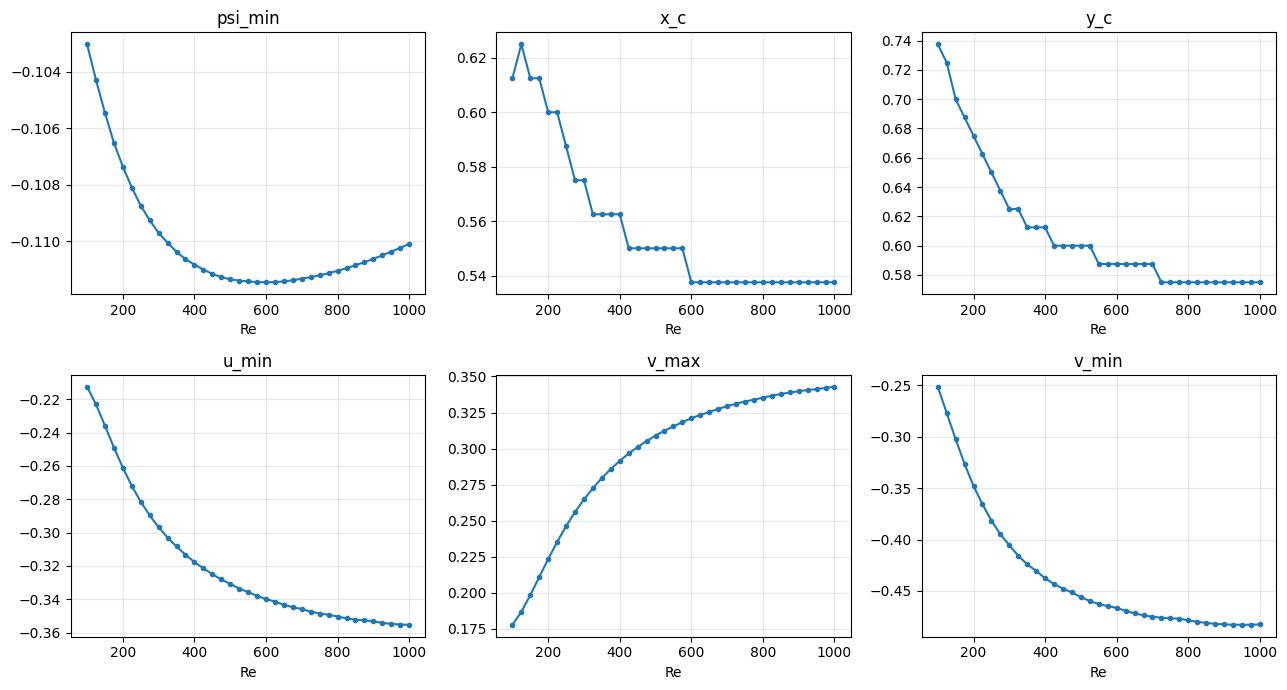

In [8]:
import pandas as pd

N_data = 81                      # grid size for the dataset
Re_list = range(100, 1001, 25)   # Re = 100, 125, 150, ..., 1000

x_data = np.linspace(0, 1, N_data)
mid = (N_data - 1) // 2          # index of the centerline (x = 0.5 or y = 0.5)

rows = []

for Re_i in Re_list:
    # run the solver
    psi_i, om_i, u_i, v_i, n_i, dt_i, ch_i = solve_cavity_fast(Re_i, N=N_data)

    # main vortex = minimum of psi
    j, i = np.unravel_index(np.argmin(psi_i), psi_i.shape)

    psi_min = psi_i[j, i]
    x_c = x_data[i]
    y_c = x_data[j]
    u_min = u_i[:, mid].min()    # vertical centerline
    v_max = v_i[mid, :].max()    # horizontal centerline
    v_min = v_i[mid, :].min()

    rows.append([Re_i, psi_min, x_c, y_c, u_min, v_max, v_min])
    print(f"Re = {Re_i} done, steps = {n_i}")

# make the table and save it
df = pd.DataFrame(rows, columns=["Re", "psi_min", "x_c", "y_c", "u_min", "v_max", "v_min"])
df.to_csv("cavity_dataset.csv", index=False)
print(df.head())

# plot every column against Re
cols = ["psi_min", "x_c", "y_c", "u_min", "v_max", "v_min"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for a, c in zip(axes.ravel(), cols):
    a.plot(df["Re"], df[c], 'o-', markersize=3)
    a.set_xlabel("Re")
    a.set_title(c)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Result:** All 37 runs finished and the data is saved in `cavity_dataset.csv`. At Re = 100 the main vortex centre is at (0.6125, 0.7375), and at Re = 1000 it moves to about (0.54, 0.57). The values of u_min, v_max and v_min get larger as Re increases. ψ_min first goes down and then goes up a little after Re ≈ 550.

**Note:** The vortex centre is taken from the nearest grid point, so x_c and y_c change in small steps.

**Conclusion:** The data changes smoothly with Re, so I can use it to train a surrogate model in the next step.

## 8. Machine Learning Model

Now I use my dataset to train a small machine learning model. The model takes only Re as input and predicts the flow features (ψ_min, x_c, y_c, u_min, v_max, v_min). So I do not need to run the full simulation every time.

I use 75% of the data to train the model and the other 25% to test it. I try two models:
- Polynomial fit (a smooth curve of degree 3)
- Random Forest

To check the models I use two numbers. RMSE is the average error, so smaller is better. R² is close to 1 when the model is good.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv("cavity_dataset.csv")
targets = ["psi_min", "x_c", "y_c", "u_min", "v_max", "v_min"]

# 75% for training, 25% for testing
train, test = train_test_split(df, test_size=0.25, random_state=42)

def r2_score_simple(y, pred):
    return 1 - np.sum((y - pred)**2) / np.sum((y - np.mean(y))**2)

rows = []
for t in targets:
    # model 1: polynomial fit of degree 3
    coef = np.polyfit(train["Re"] / 1000, train[t], 3)
    pred_poly = np.polyval(coef, test["Re"] / 1000)

    # model 2: random forest
    forest = RandomForestRegressor(n_estimators=200, random_state=42)
    forest.fit(train[["Re"]], train[t])
    pred_rf = forest.predict(test[["Re"]])

    for name, pred in [("Polynomial", pred_poly), ("Random Forest", pred_rf)]:
        rmse = np.sqrt(np.mean((test[t] - pred)**2))
        r2 = r2_score_simple(test[t], pred)
        rows.append([t, name, rmse, r2])

results_df = pd.DataFrame(rows, columns=["feature", "model", "RMSE", "R2"])
print(results_df.round(4))

    feature          model    RMSE      R2
0   psi_min     Polynomial  0.0002  0.9766
1   psi_min  Random Forest  0.0002  0.9750
2       x_c     Polynomial  0.0026  0.9854
3       x_c  Random Forest  0.0046  0.9544
4       y_c     Polynomial  0.0060  0.9671
5       y_c  Random Forest  0.0059  0.9679
6     u_min     Polynomial  0.0016  0.9971
7     u_min  Random Forest  0.0030  0.9904
8     v_max     Polynomial  0.0008  0.9996
9     v_max  Random Forest  0.0033  0.9925
10    v_min     Polynomial  0.0042  0.9908
11    v_min  Random Forest  0.0052  0.9859


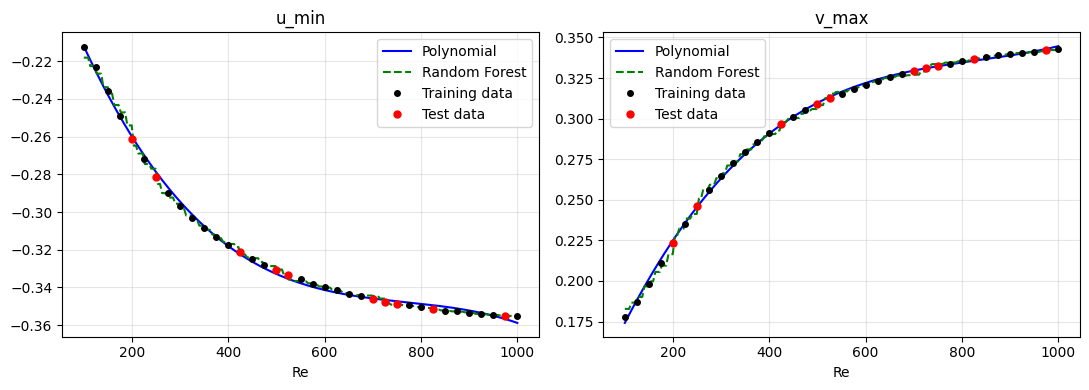

One simulation: 14.74 s
One prediction: 0.1376 ms


In [10]:
import time

Re_line = np.linspace(100, 1000, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for a, t in zip(axes, ["u_min", "v_max"]):
    coef = np.polyfit(train["Re"] / 1000, train[t], 3)
    forest = RandomForestRegressor(n_estimators=200, random_state=42)
    forest.fit(train[["Re"]], train[t])

    a.plot(Re_line, np.polyval(coef, Re_line / 1000), 'b-', label="Polynomial")
    a.plot(Re_line, forest.predict(pd.DataFrame({"Re": Re_line})), 'g--', label="Random Forest")
    a.plot(train["Re"], train[t], 'ko', markersize=4, label="Training data")
    a.plot(test["Re"], test[t], 'ro', markersize=5, label="Test data")
    a.set_xlabel("Re"); a.set_title(t); a.legend(); a.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# speed: one simulation vs one prediction
t0 = time.time()
solve_cavity_fast(550, N=81)
t_sim = time.time() - t0

t0 = time.time()
np.polyval(coef, 550 / 1000)
t_ml = time.time() - t0

print(f"One simulation: {t_sim:.2f} s")
print(f"One prediction: {t_ml*1000:.4f} ms")

**Result:** Both models predict the flow features well on the test data. The polynomial fit has R² above 0.96 for all features, and the Random Forest has R² above 0.95. The best result is for v_max (R² = 0.9996 with the polynomial). The weakest is y_c (R² = 0.967 for the polynomial and 0.968 for the Random Forest), because the vortex centre was taken from the nearest grid point and changes in small steps.

One simulation took about 14.7 seconds, but one prediction took only 0.14 milliseconds. So the prediction is about 100,000 times faster.

**Conclusion:** The model gives a good estimate of the flow features for any Re between 100 and 1000, and it is much faster than the simulation. One limitation is that I have only 37 data points and one input (Re). I should not use the model outside the range 100–1000.